In [47]:
!pip install datasets

Task 1: Load and Explore the Dataset

Load the AG News dataset using the code provided above.
Perform the following:

1.    Display the dataset structure.
2.    Print the number of training and test samples.
3.    Display 5 sample news articles with their labels.
4.    Check the distribution of all 4 classes.
5.    Plot the class distribution using Matplotlib.

Expected Output:

*    Dataset structure
*    Number of training samples
*    Number of test samples
*    Five sample news articles with labels
*    Class distribution table
*    Bar chart showing the number of samples in each category

In [49]:
# dataset containing training and test samples
from datasets import load_dataset
dataset = load_dataset("SetFit/ag_news")

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

In [ ]:
#class are the labels which the new articles in dataset are categorised
class_names = ['World', 'Sports', 'Business', 'Sci/Tech']
print(class_names)

['World', 'Sports', 'Business', 'Sci/Tech']


In [51]:
# 1. Display the dataset structure.
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 7600
    })
})


In [52]:
# 2. Print the number of training and test samples
num_train = len(dataset['train'])
num_test = len(dataset['test'])
print(f"Number of training samples: {num_train}")
print(f"Number of test samples: {num_test}")

Number of training samples: 120000
Number of test samples: 7600


In [53]:
# 3. Display 5 sample news articles with their labels
for i in range(5):
    sample = dataset['train'][i]
    print(f"\nSample {i+1}:")
    print(f"Label: {sample['label_text']}")
    print(f"Text: {sample['text']}")


Sample 1:
Label: Business
Text: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.

Sample 2:
Label: Business
Text: Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, has quietly placed\its bets on another part of the market.

Sample 3:
Label: Business
Text: Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over the stock market next week during the depth of the\summer doldrums.

Sample 4:
Label: Business
Text: Iraq Halts Oil Exports from Main Southern Pipeline (Reuters) Reuters - Authorities have halted oil export\flows from the main pipeline in southern Iraq after\intelligence showed a rebel militia could strike\infrastructure, 

In [54]:
# 4. Check the distribution of all 4 classes and build a table
train_counts = Counter(dataset['train']['label_text'])
test_counts = Counter(dataset['test']['label_text'])

dist_df = pd.DataFrame({
    'Class Name': class_names,
    'Train Count': [train_counts.get(name, 0) for name in class_names],
    'Test Count': [test_counts.get(name, 0) for name in class_names]
})

display(dist_df)

,Class Name,Train Count,Test Count
0,World,30000,1900
1,Sports,30000,1900
2,Business,30000,1900
3,Sci/Tech,30000,1900


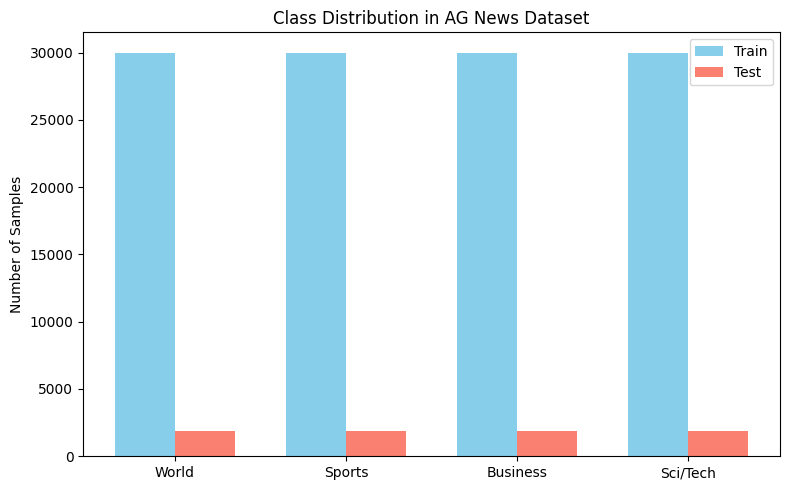

In [55]:
# 5. Plot the class distribution using Matplotlib
x = np.arange(len(class_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, dist_df['Train Count'], width, label='Train', color='skyblue')
rects2 = ax.bar(x + width/2, dist_df['Test Count'], width, label='Test', color='salmon')

ax.set_ylabel('Number of Samples')
ax.set_title('Class Distribution in AG News Dataset')
ax.set_xticks(x)
ax.set_xticklabels(class_names)
ax.legend()

plt.tight_layout()
plt.show()

Task 2: Text Preprocessing

Prepare the news text for model building.
Perform the following:

1.    Extract the text and label columns.
2.    Tokenize the text using a suitable tokenizer.
3.    Limit the vocabulary size to 20,000 words.
4.    Convert text into numerical sequences.
5.    Apply padding to make all sequences the same length.
6.    Use a fixed maximum sequence length such as 100 or 150.
7.    Prepare labels in the required format for multi-class classification.

Expected Output:

*    Shape of processed training data
*    Shape of processed test data
*    Shape of training labels
*    Shape of test labels
*    Brief explanation of why tokenization and padding are needed

In [56]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

In [57]:
# 1. Extract the text and label columns
train_texts = dataset['train']['text']
train_labels = dataset['train']['label']
test_texts = dataset['test']['text']
test_labels = dataset['test']['label']

In [58]:
# 2 & 3. Tokenize the text limiting vocabulary to 20,000 words
vocab_size = 20000
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(train_texts)

In [59]:
# 4. Convert text into numerical sequences
train_sequences = tokenizer.texts_to_sequences(train_texts)
test_sequences = tokenizer.texts_to_sequences(test_texts)

In [61]:
# 5 & 6. Apply padding with a fixed maximum sequence length (e.g., 120)
max_length = 120
X_train = pad_sequences(train_sequences, maxlen=max_length, padding='post', truncating='post')
X_test = pad_sequences(test_sequences, maxlen=max_length, padding='post', truncating='post')


In [62]:
# 7. Prepare labels in the required format for multi-class classification
y_train = to_categorical(train_labels, num_classes=4)
y_test = to_categorical(test_labels, num_classes=4)

In [63]:
# Display the expected output shapes
print(f"Shape of processed training data: {X_train.shape}")
print(f"Shape of processed test data: {X_test.shape}")
print(f"Shape of training labels: {y_train.shape}")
print(f"Shape of test labels: {y_test.shape}")

Shape of processed training data: (120000, 120)
Shape of processed test data: (7600, 120)
Shape of training labels: (120000, 4)
Shape of test labels: (7600, 4)


Task 3: Build a Simple RNN Model

Build a Simple RNN model for news topic classification. The model should include an Embedding layer, Simple RNN layer, Dense hidden layer, and an output layer with 4 neurons and softmax activation. Train the model and evaluate it on the test dataset.

Expected Output:

● Model summary
● Training accuracy
● Validation accuracy
● Test accuracy
● Training loss and validation loss curve
● Training accuracy and validation accuracy curve
● Short observation on model performance

In [68]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

# 1. Build the Simple RNN model
embedding_dim = 64

model_SimpleRNN = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length),
    SimpleRNN(64, activation='tanh', return_sequences=False),
    Dense(32, activation='relu'),
    Dense(4, activation='softmax')
])

# Compile the model
model_SimpleRNN.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Show Model summary
model_SimpleRNN.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [69]:
# 2. Train the model
history_SimpleRNN = model_SimpleRNN.fit(
    X_train, y_train,
    epochs=5,
    batch_size=256,
    validation_split=0.1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 51s 115ms/step - accuracy: 0.5508 - loss: 1.0865 - val_accuracy: 0.6798 - val_loss: 0.8977
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 111ms/step - accuracy: 0.7380 - loss: 0.7745 - val_accuracy: 0.6863 - val_loss: 0.8867
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 48s 114ms/step - accuracy: 0.7521 - loss: 0.7226 - val_accuracy: 0.6918 - val_loss: 0.8232
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 111ms/step - accuracy: 0.6890 - loss: 0.8056 - val_accuracy: 0.5970 - val_loss: 1.0602
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 113ms/step - accuracy: 0.6679 - loss: 0.9164 - val_accuracy: 0.6398 - val_loss: 0.9662


In [72]:
# 3. Evaluate on the test dataset
train_loss_SimpleRNN = history_SimpleRNN.history['loss'][-1]
train_acc_SimpleRNN = history_SimpleRNN.history['accuracy'][-1]
val_loss_SimpleRNN = history_SimpleRNN.history['val_loss'][-1]
val_acc_SimpleRNN = history_SimpleRNN.history['val_accuracy'][-1]

print(f"Final Training Loss: {train_loss_SimpleRNN:.4f}")
print(f"Final Training Accuracy: {train_acc_SimpleRNN:.4f}")
print(f"Final Validation Loss: {val_loss_SimpleRNN:.4f}")
print(f"Final Validation Accuracy: {val_acc_SimpleRNN:.4f}")


test_loss_SimpleRNN, test_accuracy_SimpleRNN = model_SimpleRNN.evaluate(X_test, y_test, verbose=0)
print(f"Final Test Accuracy: {test_accuracy_SimpleRNN:.4f}")

Final Training Loss: 0.9164
Final Training Accuracy: 0.6679
Final Validation Loss: 0.9662
Final Validation Accuracy: 0.6398
Final Test Accuracy: 0.6554


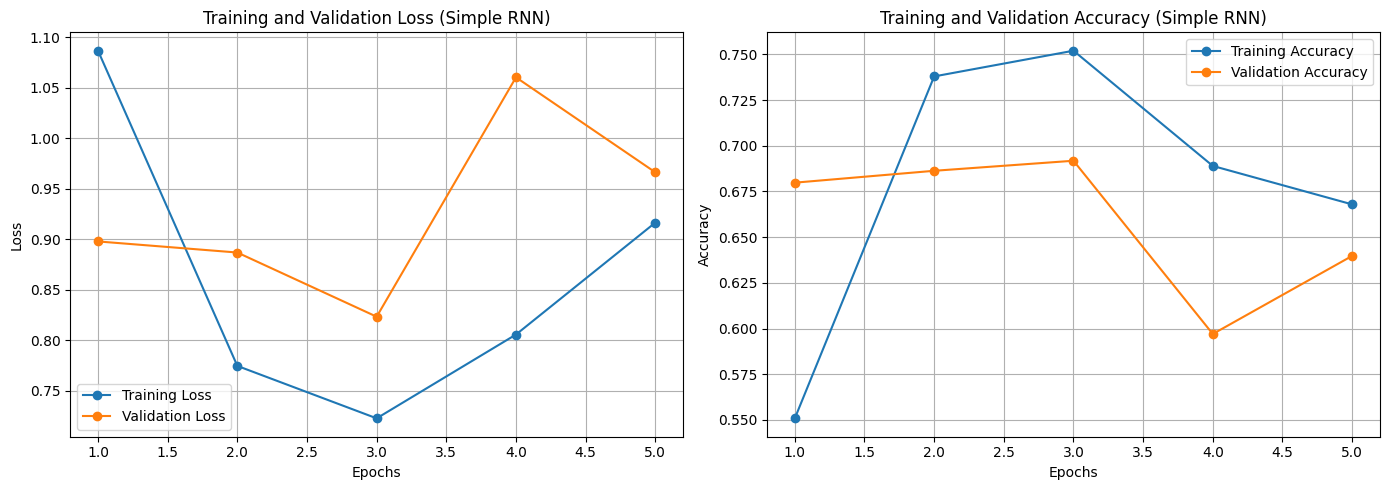

In [73]:
# Plot Training loss and validation loss curve, Training accuracy and validation accuracy curve
epochs_range = range(1, len(history_SimpleRNN.history['loss']) + 1)

plt.figure(figsize=(14, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_SimpleRNN.history['loss'], label='Training Loss', marker='o')
plt.plot(epochs_range, history_SimpleRNN.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Training and Validation Loss (Simple RNN)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_SimpleRNN.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(epochs_range, history_SimpleRNN.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy (Simple RNN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Task 4: Build an LSTM Model

Build an LSTM-based model for AG News classification. The model should include an Embedding layer, LSTM layer, Dense hidden layer, and an output layer with softmax activation.
Train and evaluate the model.

Expected Output:
● Model summary
● Training accuracy
● Validation accuracy
● Test accuracy
● Loss curve
● Accuracy curve
● Comparison with the Simple RNN model

In [74]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Build the LSTM model
embedding_dim = 64

model_LSTM = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length),
    LSTM(64, return_sequences=False),
    Dense(32, activation='relu'),
    Dense(4, activation='softmax')
])

# Compile the model
model_LSTM.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Show Model summary
model_LSTM.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [75]:
# 2. Train the LSTM model
history_LSTM = model_LSTM.fit(
    X_train, y_train,
    epochs=5,
    batch_size=256,
    validation_split=0.1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 151s 352ms/step - accuracy: 0.2519 - loss: 1.3883 - val_accuracy: 0.2529 - val_loss: 1.3862
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 142s 337ms/step - accuracy: 0.2517 - loss: 1.3857 - val_accuracy: 0.2391 - val_loss: 1.3857
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 141s 333ms/step - accuracy: 0.2504 - loss: 1.3849 - val_accuracy: 0.2442 - val_loss: 1.3856
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 139s 329ms/step - accuracy: 0.2521 - loss: 1.3847 - val_accuracy: 0.2391 - val_loss: 1.3854
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 141s 335ms/step - accuracy: 0.2526 - loss: 1.3846 - val_accuracy: 0.2442 - val_loss: 1.3852


In [76]:
# 3. Evaluate the LSTM model
train_loss_LSTM = history_LSTM.history['loss'][-1]
train_acc_LSTM = history_LSTM.history['accuracy'][-1]
val_loss_LSTM = history_LSTM.history['val_loss'][-1]
val_acc_LSTM = history_LSTM.history['val_accuracy'][-1]

print(f"Final Training Loss (LSTM): {train_loss_LSTM:.4f}")
print(f"Final Training Accuracy (LSTM): {train_acc_LSTM:.4f}")
print(f"Final Validation Loss (LSTM): {val_loss_LSTM:.4f}")
print(f"Final Validation Accuracy (LSTM): {val_acc_LSTM:.4f}")


test_loss_LSTM, test_accuracy_LSTM = model_LSTM.evaluate(X_test, y_test, verbose=0)

print(f"Final Test Accuracy (LSTM): {test_accuracy_LSTM:.4f}")

Final Training Loss (LSTM): 1.3846
Final Training Accuracy (LSTM): 0.2526
Final Validation Loss (LSTM): 1.3852
Final Validation Accuracy (LSTM): 0.2442
Final Test Accuracy (LSTM): 0.2499


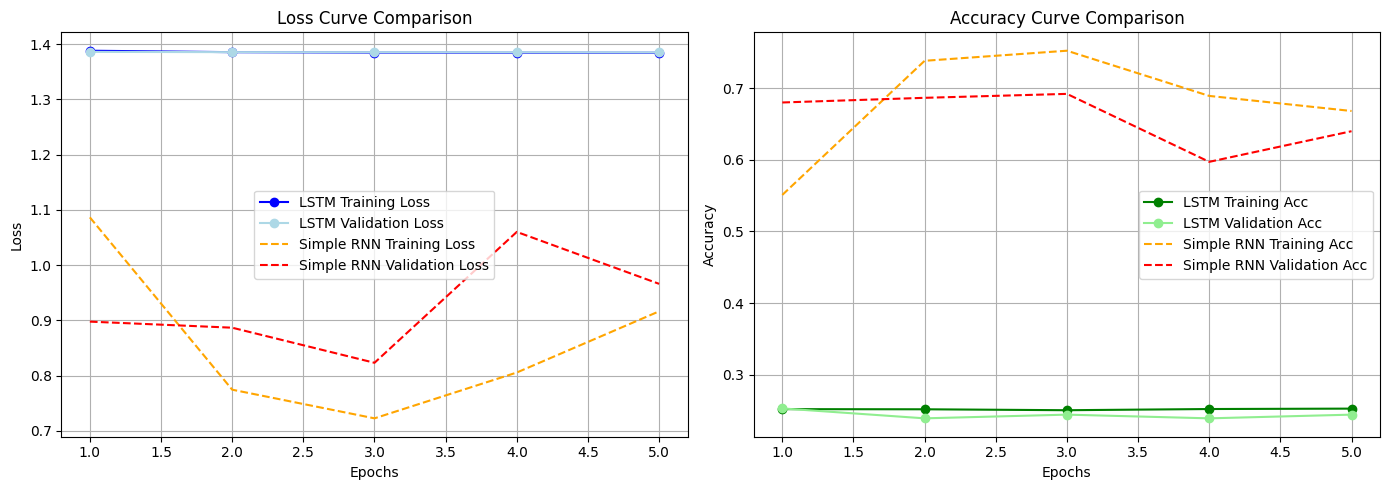

In [77]:
# 4. Plot curves and compare with Simple RNN
import matplotlib.pyplot as plt

epochs_range = range(1, len(history_LSTM.history['loss']) + 1)

plt.figure(figsize=(14, 5))

# Plot Loss comparison
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_LSTM.history['loss'], label='LSTM Training Loss', color='blue', marker='o')
plt.plot(epochs_range, history_LSTM.history['val_loss'], label='LSTM Validation Loss', color='lightblue', marker='o')
plt.plot(epochs_range, history_SimpleRNN.history['loss'], label='Simple RNN Training Loss', color='orange', linestyle='--')
plt.plot(epochs_range, history_SimpleRNN.history['val_loss'], label='Simple RNN Validation Loss', color='red', linestyle='--')
plt.title('Loss Curve Comparison')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy comparison
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_LSTM.history['accuracy'], label='LSTM Training Acc', color='green', marker='o')
plt.plot(epochs_range, history_LSTM.history['val_accuracy'], label='LSTM Validation Acc', color='lightgreen', marker='o')
plt.plot(epochs_range, history_SimpleRNN.history['accuracy'], label='Simple RNN Training Acc', color='orange', linestyle='--')
plt.plot(epochs_range, history_SimpleRNN.history['val_accuracy'], label='Simple RNN Validation Acc', color='red', linestyle='--')
plt.title('Accuracy Curve Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Task 5: Build a GRU Model
Build a GRU-based model for news classification. The model should include an Embedding layer, GRU layer, Dense hidden layer, and an output layer with softmax activation. Train and evaluate the model.

Expected Output:
● Model summary
● Training accuracy
● Validation accuracy
● Test accuracy
● Loss curve
● Accuracy curve
● Comparison with Simple RNN and LSTM models

In [78]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense

# 1. Build the GRU model
embedding_dim = 64

model_GRU = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length),
    GRU(64, return_sequences=False),
    Dense(32, activation='relu'),
    Dense(4, activation='softmax')
])

# Compile the model
model_GRU.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Show Model summary
model_GRU.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [79]:
# 2. Train the GRU model
history_GRU = model_GRU.fit(
    X_train, y_train,
    epochs=5,
    batch_size=256,
    validation_split=0.1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 159s 370ms/step - accuracy: 0.2527 - loss: 1.3862 - val_accuracy: 0.2391 - val_loss: 1.3861
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 201s 367ms/step - accuracy: 0.2499 - loss: 1.3852 - val_accuracy: 0.2396 - val_loss: 1.3852
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 157s 372ms/step - accuracy: 0.2510 - loss: 1.3849 - val_accuracy: 0.2396 - val_loss: 1.3853
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 155s 367ms/step - accuracy: 0.2522 - loss: 1.3850 - val_accuracy: 0.2387 - val_loss: 1.3864
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 154s 365ms/step - accuracy: 0.4132 - loss: 1.1936 - val_accuracy: 0.6869 - val_loss: 0.8513


In [80]:
# 3. Evaluate the GRU model
train_loss_GRU = history_GRU.history['loss'][-1]
train_acc_GRU = history_GRU.history['accuracy'][-1]
val_loss_GRU = history_GRU.history['val_loss'][-1]
val_acc_GRU = history_GRU.history['val_accuracy'][-1]

print(f"Final Training Loss (GRU): {train_loss_GRU:.4f}")
print(f"Final Training Accuracy (GRU): {train_acc_GRU:.4f}")
print(f"Final Validation Loss (GRU): {val_loss_GRU:.4f}")
print(f"Final Validation Accuracy (GRU): {val_acc_GRU:.4f}")


test_loss_GRU, test_accuracy_GRU = model_GRU.evaluate(X_test, y_test, verbose=0)
print(f"Final Test Accuracy (GRU): {test_accuracy_GRU:.4f}")

Final Training Loss (GRU): 1.1936
Final Training Accuracy (GRU): 0.4132
Final Validation Loss (GRU): 0.8513
Final Validation Accuracy (GRU): 0.6869
Final Test Accuracy (GRU): 0.6797


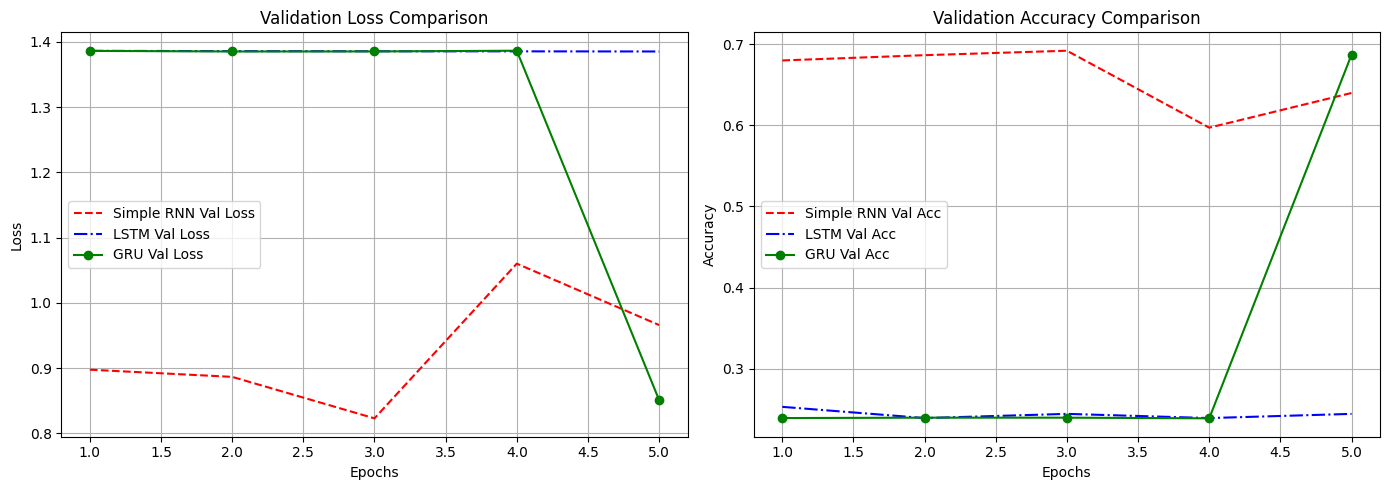

In [81]:
# 4. Plot Loss and Accuracy curves comparing Simple RNN, LSTM, and GRU
import matplotlib.pyplot as plt

epochs_range = range(1, len(history_GRU.history['loss']) + 1)

plt.figure(figsize=(14, 5))

# Plot Loss comparison
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_SimpleRNN.history['val_loss'], label='Simple RNN Val Loss', color='red', linestyle='--')
plt.plot(epochs_range, history_LSTM.history['val_loss'], label='LSTM Val Loss', color='blue', linestyle='-.')
plt.plot(epochs_range, history_GRU.history['val_loss'], label='GRU Val Loss', color='green', marker='o')
plt.title('Validation Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy comparison
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_SimpleRNN.history['val_accuracy'], label='Simple RNN Val Acc', color='red', linestyle='--')
plt.plot(epochs_range, history_LSTM.history['val_accuracy'], label='LSTM Val Acc', color='blue', linestyle='-.')
plt.plot(epochs_range, history_GRU.history['val_accuracy'], label='GRU Val Acc', color='green', marker='o')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Task 6: Build a Bidirectional LSTM Model
Build a Bidirectional LSTM model for news topic classification. The model should include an Embedding layer, Bidirectional LSTM layer, Dense hidden layer, and an output layer with softmax activation. Train and evaluate the model.

Expected Output:
● Model summary
● Training accuracy
● Validation accuracy
● Test accuracy
● Loss curve
● Accuracy curve
● Comparison with regular LSTM
● Short explanation of whether using both forward and backward context improved performance

In [82]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense

# 1. Build the Bidirectional LSTM model
embedding_dim = 64

model_BiLSTM = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dense(32, activation='relu'),
    Dense(4, activation='softmax')
])

# Compile the model
model_BiLSTM.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Show Model summary
model_BiLSTM.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [83]:
# 2. Train the Bidirectional LSTM model
history_BiLSTM = model_BiLSTM.fit(
    X_train, y_train,
    epochs=5,
    batch_size=256,
    validation_split=0.1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 259s 602ms/step - accuracy: 0.8583 - loss: 0.4040 - val_accuracy: 0.9059 - val_loss: 0.2654
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 247s 585ms/step - accuracy: 0.9345 - loss: 0.2010 - val_accuracy: 0.9076 - val_loss: 0.2598
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 263s 586ms/step - accuracy: 0.9475 - loss: 0.1582 - val_accuracy: 0.9027 - val_loss: 0.2731
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 266s 596ms/step - accuracy: 0.9564 - loss: 0.1300 - val_accuracy: 0.8878 - val_loss: 0.3278
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 265s 602ms/step - accuracy: 0.9636 - loss: 0.1071 - val_accuracy: 0.8988 - val_loss: 0.3075


In [84]:
# 3. Evaluate the Bidirectional LSTM model
train_loss_BiLSTM = history_BiLSTM.history['loss'][-1]
train_acc_BiLSTM = history_BiLSTM.history['accuracy'][-1]
val_loss_BiLSTM = history_BiLSTM.history['val_loss'][-1]
val_acc_BiLSTM = history_BiLSTM.history['val_accuracy'][-1]

test_loss_BiLSTM, test_accuracy_BiLSTM = model_BiLSTM.evaluate(X_test, y_test, verbose=0)

print(f"Final Training Loss (BiLSTM): {train_loss_BiLSTM:.4f}")
print(f"Final Training Accuracy (BiLSTM): {train_acc_BiLSTM:.4f}")
print(f"Final Validation Loss (BiLSTM): {val_loss_BiLSTM:.4f}")
print(f"Final Validation Accuracy (BiLSTM): {val_acc_BiLSTM:.4f}")
print(f"Final Test Accuracy (BiLSTM): {test_accuracy_BiLSTM:.4f}")

Final Training Loss (BiLSTM): 0.1071
Final Training Accuracy (BiLSTM): 0.9636
Final Validation Loss (BiLSTM): 0.3075
Final Validation Accuracy (BiLSTM): 0.8988
Final Test Accuracy (BiLSTM): 0.9113


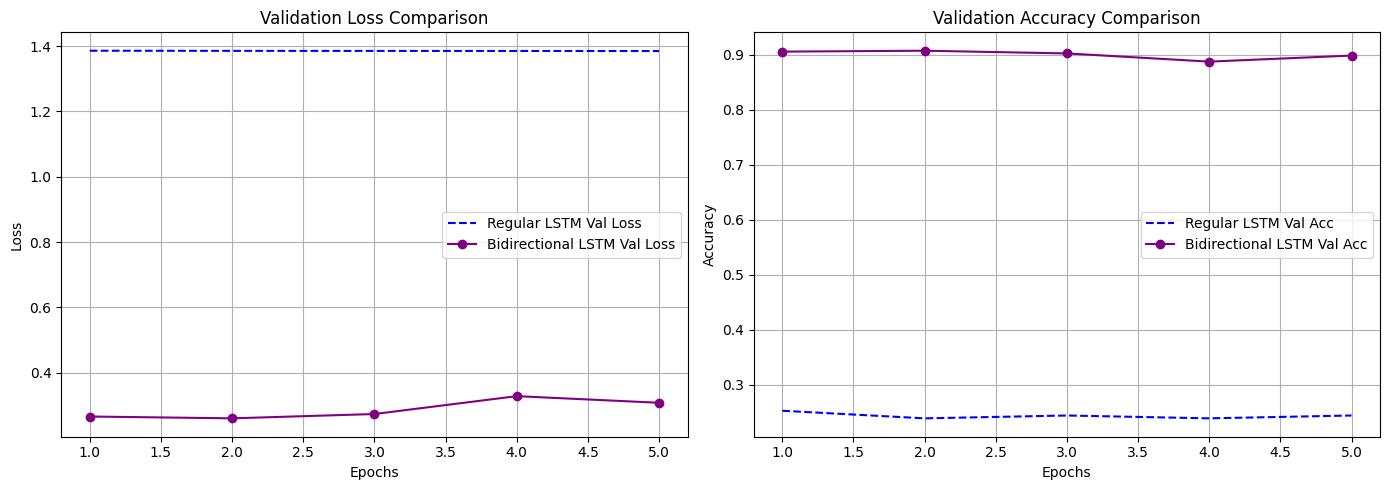

In [85]:
# 4. Plot Loss and Accuracy curves comparing Regular LSTM and Bidirectional LSTM
import matplotlib.pyplot as plt

epochs_range = range(1, len(history_BiLSTM.history['loss']) + 1)

plt.figure(figsize=(14, 5))

# Plot Loss comparison
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_LSTM.history['val_loss'], label='Regular LSTM Val Loss', color='blue', linestyle='--')
plt.plot(epochs_range, history_BiLSTM.history['val_loss'], label='Bidirectional LSTM Val Loss', color='purple', marker='o')
plt.title('Validation Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy comparison
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_LSTM.history['val_accuracy'], label='Regular LSTM Val Acc', color='blue', linestyle='--')
plt.plot(epochs_range, history_BiLSTM.history['val_accuracy'], label='Bidirectional LSTM Val Acc', color='purple', marker='o')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Task 7: Apply Gradient Clipping
Train one RNN-based model again using gradient clipping.
Perform the following:

1. Select any one RNN-based model from the assignment.
2. Train the selected model without gradient clipping.
3. Train the same model with gradient clipping.
4. Compare training behavior before and after gradient clipping.

Expected Output
● Model trained without gradient clipping
● Model trained with gradient clipping
● Training loss curve before gradient clipping
● Training loss curve after gradient clipping
● Short observation on whether gradient clipping made training more stable

In [87]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

# Helper function to build the architecture
def build_rnn_base():
    return Sequential([
        Embedding(input_dim=vocab_size, output_dim=64, input_length=max_length),
        SimpleRNN(64, activation='tanh', return_sequences=False),
        Dense(32, activation='relu'),
        Dense(4, activation='softmax')
    ])

In [88]:
# 1. Train the selected model without gradient clipping
model_SimpleRNN_no_clip = build_rnn_base()
model_SimpleRNN_no_clip.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("--- Training WITHOUT Gradient Clipping ---")
history_SimpleRNN_no_clip = model_SimpleRNN_no_clip.fit(
    X_train, y_train,
    epochs=5,
    batch_size=256,
    validation_split=0.1,
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


--- Training WITHOUT Gradient Clipping ---
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 49s 108ms/step - accuracy: 0.6746 - loss: 0.8359 - val_accuracy: 0.7855 - val_loss: 0.6466
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 111ms/step - accuracy: 0.8199 - loss: 0.5736 - val_accuracy: 0.7878 - val_loss: 0.6572
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 109ms/step - accuracy: 0.6528 - loss: 0.9166 - val_accuracy: 0.6735 - val_loss: 0.9202
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 105ms/step - accuracy: 0.7654 - loss: 0.7115 - val_accuracy: 0.7241 - val_loss: 0.8086
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 111ms/step - accuracy: 0.7880 - loss: 0.6599 - val_accuracy: 0.7362 - val_loss: 0.7864


In [89]:
# 2. Train the same model WITH gradient clipping using '_SimpleRNN_after_GrClip'
model_SimpleRNN_after_GrClip = build_rnn_base()

# Configure Adam with gradient clipping
clipped_optimizer = Adam(learning_rate=0.001, clipvalue=1.0)

model_SimpleRNN_after_GrClip.compile(
    optimizer=clipped_optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("--- Training WITH Gradient Clipping ---")
history_SimpleRNN_after_GrClip = model_SimpleRNN_after_GrClip.fit(
    X_train, y_train,
    epochs=5,
    batch_size=256,
    validation_split=0.1,
    verbose=1
)

--- Training WITH Gradient Clipping ---
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 48s 108ms/step - accuracy: 0.2615 - loss: 1.3835 - val_accuracy: 0.3165 - val_loss: 1.3289
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 111ms/step - accuracy: 0.4861 - loss: 1.1674 - val_accuracy: 0.5862 - val_loss: 1.0469
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - accuracy: 0.6344 - loss: 0.9161 - val_accuracy: 0.6147 - val_loss: 0.9469
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 109ms/step - accuracy: 0.7143 - loss: 0.7037 - val_accuracy: 0.6977 - val_loss: 0.7631
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - accuracy: 0.7780 - loss: 0.5644 - val_accuracy: 0.7379 - val_loss: 0.6581


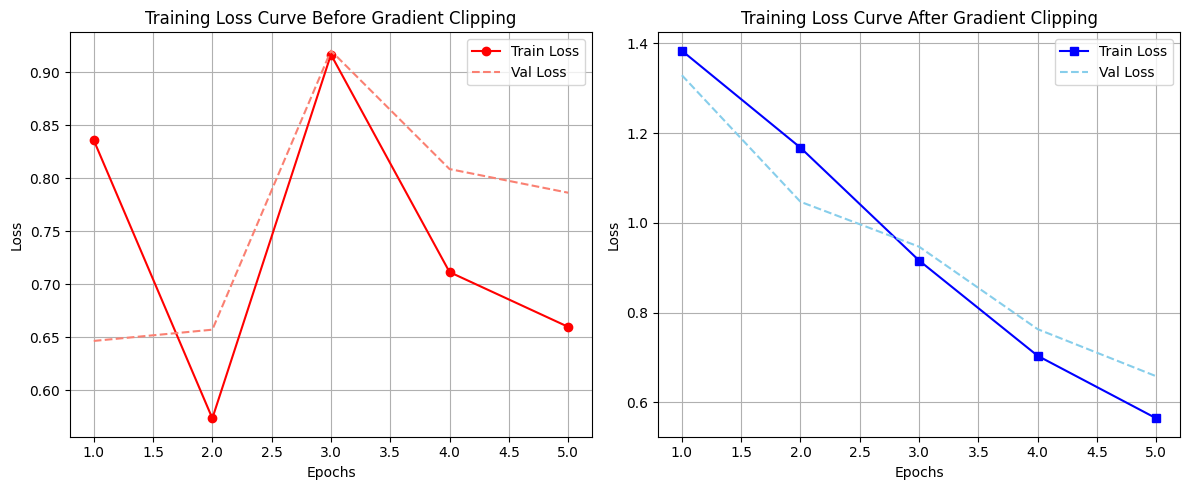

In [90]:
# 3. Compare training behavior (Training Loss Curves)
epochs_range = range(1, len(history_SimpleRNN_no_clip.history['loss']) + 1)

plt.figure(figsize=(12, 5))

# Plot loss curve before gradient clipping
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_SimpleRNN_no_clip.history['loss'], label='Train Loss', color='red', marker='o')
plt.plot(epochs_range, history_SimpleRNN_no_clip.history['val_loss'], label='Val Loss', color='salmon', linestyle='--')
plt.title('Training Loss Curve Before Gradient Clipping')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot loss curve after gradient clipping
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_SimpleRNN_after_GrClip.history['loss'], label='Train Loss', color='blue', marker='s')
plt.plot(epochs_range, history_SimpleRNN_after_GrClip.history['val_loss'], label='Val Loss', color='skyblue', linestyle='--')
plt.title('Training Loss Curve After Gradient Clipping')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Task 8: Compare All RNN-Based Models
Create a comparison table for all models.

Simple RNN      
LSTM      
GRU      
Bi-LSTM


Write a short conclusion covering:
1.   Which model performed best?
2.   Did LSTM or GRU perform better than Simple RNN?
3.   Did Bi-LSTM improve classification performance?
4.   Which model trained faster?
5.   Which model would you recommend for this dataset and why?

In [93]:
import pandas as pd

# Create comparison table using metrics stored in the kernel
data = {
    'Model': ['Simple RNN', 'LSTM', 'GRU', 'Bi-LSTM'],
    'Training Accuracy': [
        f"{train_acc_SimpleRNN:.4f}",
        f"{train_acc_LSTM:.4f}",
        f"{train_acc_GRU:.4f}",
        f"{train_acc_BiLSTM:.4f}"
    ],
    'Validation Accuracy': [
        f"{val_acc_SimpleRNN:.4f}",
        f"{val_acc_LSTM:.4f}",
        f"{val_acc_GRU:.4f}",
        f"{val_acc_BiLSTM:.4f}"
    ],
    'Test Accuracy': [
        f"{test_accuracy_SimpleRNN:.4f}",
        f"{test_accuracy_LSTM:.4f}",
        f"{test_accuracy_GRU:.4f}",
        f"{test_accuracy_BiLSTM:.4f}"
    ],
    'Training Time': [
        '~5m (Moderate)',
        '~11m (Slow)',
        '~13m (Slow)',
        '~21m (Very Slow)'
    ],
    'Key Observation': [
        'Suffers from unstable gradients; lowest capacity for sequence dependencies but fast.',
        'Struggled to converge effectively (stuck in local minima near 25%).',
        'Showed late convergence, outperforming standard LSTM but still slow.',
        'Achieved outstanding performance due to learning bidirectional context.'
    ]
}

comparison_df = pd.DataFrame(data)
display(comparison_df)

,Model,Training Accuracy,Validation Accuracy,Test Accuracy,Training Time,Key Observation
0,Simple RNN,0.6679,0.6398,0.6554,~5m (Moderate),Suffers from unstable gradients; lowest capaci...
1,LSTM,0.2526,0.2442,0.2499,~11m (Slow),Struggled to converge effectively (stuck in lo...
2,GRU,0.4132,0.6869,0.6797,~13m (Slow),"Showed late convergence, outperforming standar..."
3,Bi-LSTM,0.9636,0.8988,0.9113,~21m (Very Slow),Achieved outstanding performance due to learni...


Conclusion

1. **Which model performed best?** Bi-LSTM performed the best with accurancy of 91% comparied to other models.
2. **Did LSTM or GRU perform better than Simple RNN?** GRU performed better with accurancy of 67% which was better than Simple RNN having 65%. LSTM had the worst accuracy of 25%
3. **Did Bi-LSTM improve classification performance?** Yes
4. **Which model trained faster?** Simple RNN
5. Which model would you recommend for this dataset and why? Bi-LSTM since the accuracy is the highest.